# M113 — Clustering K-means : profils types d'étudiants

Objectif : appliquer K-means sur les caractéristiques retenues par l'arbre de décision, déterminer le nombre optimal de clusters (silhouette score), interpréter les centroïdes, puis comparer les clusters aux étiquettes réelles (Dropout / Enrolled / Graduate) pour voir si des profils à risque apparaissent naturellement.

In [25]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd()
SHARED = ROOT / "shared"
RESULTS = ROOT / "results" / "task3"
FIGURES = RESULTS / "figures"
for directory in [RESULTS, FIGURES]:
    directory.mkdir(parents=True, exist_ok=True)

SEED = 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Racine du projet", ROOT)

Racine du projet c:\Users\setup game\Downloads\prjtml\student-dropout-prediction


## 1. Chargement des données partagées

On réutilise exactement les fichiers produits par l'étape de préparation (`shared/`) : même découpage train / validation, mêmes caractéristiques retenues par l'arbre de décision. L'identifiant `row_id` sert uniquement aux jointures.

In [26]:
def read_shared(name):
    df = pd.read_csv(SHARED / name)
    if "row_id" in df.columns:
        df = df.set_index("row_id")
    return df

X_train = read_shared("X_train.csv")
X_val = read_shared("X_val.csv")
labels = read_shared("labels.csv")
clean = read_shared("data_clean.csv")

with open(SHARED / "selected_features.json", encoding="utf-8") as f:
    selected = json.load(f)
# le fichier peut être une liste ou un dictionnaire contenant la liste
if isinstance(selected, dict):
    selected = next(v for v in selected.values() if isinstance(v, list))
features = [c for c in selected if c in X_train.columns]

print("Caractéristiques retenues :", features)
X_train, X_val = X_train[features], X_val[features]
print(labels.columns.tolist())
display(labels.head())

if "Target" in labels.columns:
    target_col = "Target"
else:
    target_col = [c for c in labels.columns if c != "split"][0]
y = labels[target_col].loc[X_train.index]
print("Colonne utilisée :", target_col)
display(y.value_counts())
print("Train", X_train.shape, "| Val", X_val.shape)
display(y.value_counts().to_frame("effectif"))
display(X_train.head())

Caractéristiques retenues : ['Curricular units 2nd sem (approved)', 'Tuition fees up to date', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (approved)', 'Age at enrollment', 'Curricular units 2nd sem (evaluations)', 'Curricular units 1st sem (evaluations)', 'Curricular units 2nd sem (grade)', 'Admission grade', 'Curricular units 2nd sem (enrolled)', 'Curricular units 1st sem (grade)']
['split', 'Target']


,split,Target
row_id,,
0,train,Dropout
1,train,Graduate
2,train,Dropout
3,train,Graduate
4,train,Graduate


Colonne utilisée : Target


Target
Graduate    1325
Dropout      852
Enrolled     476
Name: count, dtype: int64

Train (2653, 11) | Val (883, 11)


,effectif
Target,
Graduate,1325
Dropout,852
Enrolled,476


,Curricular units 2nd sem (approved),Tuition fees up to date,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Age at enrollment,Curricular units 2nd sem (evaluations),Curricular units 1st sem (evaluations),Curricular units 2nd sem (grade),Admission grade,Curricular units 2nd sem (enrolled),Curricular units 1st sem (grade)
row_id,,,,,,,,,,,
0,0.0,1.0,0.0,0.0,20.0,0.0,0.0,0.000000,127.3,0.0,0.000000
1,6.0,0.0,6.0,6.0,19.0,6.0,6.0,13.666667,142.5,6.0,14.000000
2,0.0,0.0,6.0,0.0,19.0,0.0,0.0,0.000000,124.8,6.0,0.000000
3,5.0,1.0,6.0,6.0,20.0,10.0,8.0,12.400000,119.6,6.0,13.428571
4,6.0,1.0,6.0,5.0,45.0,6.0,9.0,13.000000,141.5,6.0,12.333333


## 2. Contrôle des variables avant K-means

K-means repose sur la distance euclidienne : toutes les variables doivent être numériques et sur une échelle comparable, sinon celles qui ont la plus grande amplitude dominent le calcul. On vérifie donc les types et la standardisation, et on standardise (moyenne et écart-type calculés sur le train uniquement) si ce n'est pas déjà fait.

In [27]:
assert all(pd.api.types.is_numeric_dtype(t) for t in X_train.dtypes), "Variables non numériques : les encoder avant K-means"
assert not X_train.isna().any().any()

already_scaled = np.allclose(X_train.mean(), 0, atol=0.1) and np.allclose(X_train.std(ddof=0), 1, atol=0.1)
if already_scaled:
    Xtr, Xva = X_train.to_numpy(float), X_val.to_numpy(float)
    scaler = None
    print("Données déjà standardisées.")
else:
    scaler = StandardScaler().fit(X_train)
    Xtr, Xva = scaler.transform(X_train), scaler.transform(X_val)
    print("Standardisation appliquée (ajustée sur le train).")

Standardisation appliquée (ajustée sur le train).


## 3. Nombre optimal de clusters

On teste k de 2 à 10. Critère principal : le silhouette score (à maximiser). On regarde aussi l'inertie (méthode du coude) et l'indice de Davies-Bouldin (à minimiser) pour confirmer le choix.

,inertie,silhouette,davies_bouldin
k,,,
2,20149.164,0.430,1.131
3,15537.828,0.445,1.031
4,13831.320,0.285,1.537
5,12568.259,0.247,1.437
6,11401.929,0.253,1.393
7,10409.842,0.221,1.293
8,9655.374,0.224,1.348
9,9023.055,0.228,1.313
10,8524.899,0.221,1.352


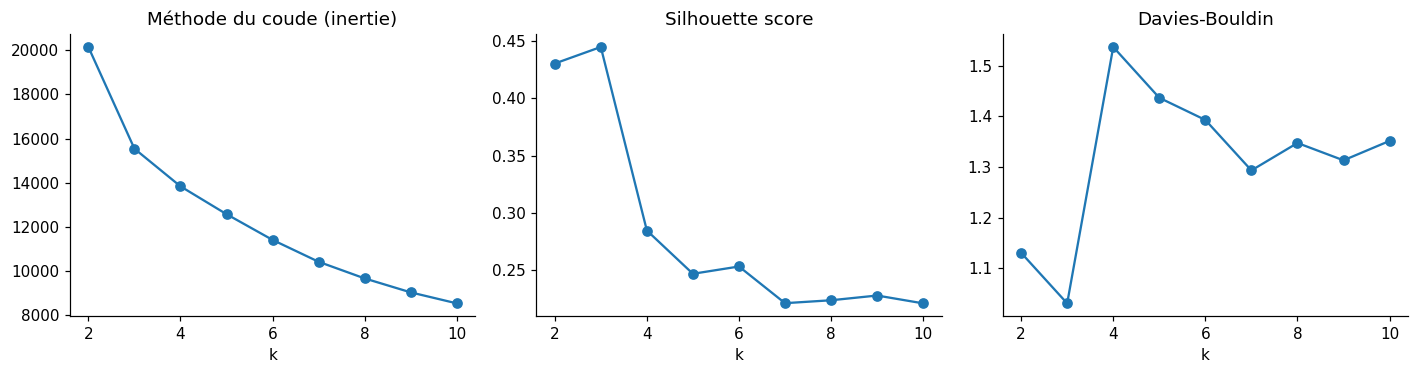

k retenu (silhouette maximal) : 3


In [28]:
ks = list(range(2, 11))
rows = []
for k in ks:
    km_k = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=SEED).fit(Xtr)
    rows.append({"k": k, "inertie": km_k.inertia_,
                 "silhouette": silhouette_score(Xtr, km_k.labels_),
                 "davies_bouldin": davies_bouldin_score(Xtr, km_k.labels_)})
scores = pd.DataFrame(rows).set_index("k")
display(scores.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col, title in zip(axes, ["inertie", "silhouette", "davies_bouldin"],
                          ["Méthode du coude (inertie)", "Silhouette score", "Davies-Bouldin"]):
    ax.plot(scores.index, scores[col], "o-")
    ax.set(title=title, xlabel="k")
plt.tight_layout()
plt.savefig(FIGURES / "choix_k.png", bbox_inches="tight")
plt.show()

K = int(scores["silhouette"].idxmax())
print("k retenu (silhouette maximal) :", K)

### Diagramme de silhouette pour le k retenu

Chaque barre est un étudiant : un cluster dont les barres sont longues et régulières est compact et bien séparé ; des valeurs négatives indiquent des étudiants plus proches d'un autre cluster que du leur.

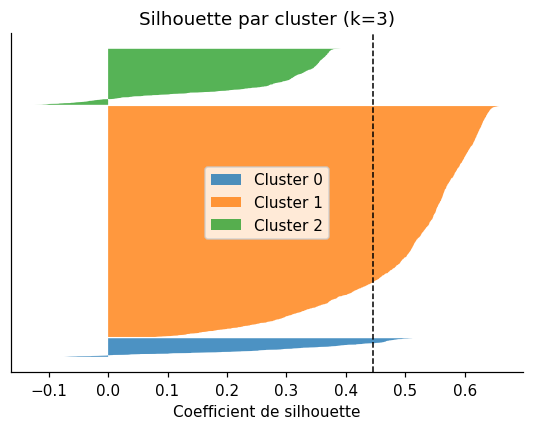

In [29]:
km_best = KMeans(n_clusters=K, init="k-means++", n_init=20, random_state=SEED).fit(Xtr)
sil_samples = silhouette_samples(Xtr, km_best.labels_)

fig, ax = plt.subplots(figsize=(6, 4))
y_lower = 10
for c in range(K):
    vals = np.sort(sil_samples[km_best.labels_ == c])
    ax.fill_betweenx(np.arange(y_lower, y_lower + len(vals)), 0, vals, alpha=0.8, label=f"Cluster {c}")
    y_lower += len(vals) + 10
ax.axvline(sil_samples.mean(), color="k", ls="--", lw=1)
ax.set(title=f"Silhouette par cluster (k={K})", xlabel="Coefficient de silhouette", yticks=[])
ax.legend()
plt.savefig(FIGURES / "silhouette_clusters.png", bbox_inches="tight")
plt.show()

## 4. Choix de l'initialisation et stabilité

Par rapport à la variante standard (centres initiaux aléatoires, une seule exécution), on utilise k-means++ avec plusieurs initialisations (`n_init`) et on garde la meilleure inertie. On le justifie ici par deux mesures : (1) inertie et nombre d'itérations sur 20 graines pour les deux initialisations, (2) stabilité des clusters entre graines via l'indice de Rand ajusté (ARI).

In [30]:
rows = []
for init in ["random", "k-means++"]:
    for seed in range(20):
        m = KMeans(n_clusters=K, init=init, n_init=1, random_state=seed).fit(Xtr)
        rows.append({"initialisation": init, "inertie": m.inertia_, "itérations": m.n_iter_})
comparaison = pd.DataFrame(rows).groupby("initialisation").agg(["mean", "std"]).round(2)
display(comparaison)

refs = [KMeans(n_clusters=K, init="k-means++", n_init=20, random_state=s).fit(Xtr).labels_ for s in range(10)]
ari = [adjusted_rand_score(refs[0], r) for r in refs[1:]]
print(f"Stabilité (ARI entre graines, n_init=20) : moyenne {np.mean(ari):.3f}, min {np.min(ari):.3f}")

inertie          itérations       
                    mean      std       mean    std
initialisation                                     
k-means++       16150.60  1259.34       9.60   6.83
random          16150.61  1259.36      14.25  10.65

Stabilité (ARI entre graines, n_init=20) : moyenne 1.000, min 1.000


## 5. Modèle final

On ajuste le modèle final sur le train, puis on assigne les étudiants de validation à leur centroïde le plus proche pour vérifier que la structure se généralise.

In [31]:
km = KMeans(n_clusters=K, init="k-means++", n_init=50, random_state=SEED).fit(Xtr)
train_clusters = km.labels_
val_clusters = km.predict(Xva)

print("Taille des clusters (train) :", np.bincount(train_clusters))
print("Silhouette train :", round(silhouette_score(Xtr, train_clusters), 3))
print("Silhouette val   :", round(silhouette_score(Xva, val_clusters), 3))

Taille des clusters (train) : [ 162 2004  487]
Silhouette train : 0.445
Silhouette val   : 0.458


## 6. Interprétation des centroïdes

Deux lectures complémentaires : (a) les centroïdes standardisés montrent quelles caractéristiques distinguent chaque cluster par rapport à la moyenne générale (0 = moyenne, ±1 = un écart-type) ; (b) les moyennes en unités d'origine, calculées depuis `data_clean.csv`, donnent des valeurs concrètes (notes, nombre d'unités validées, etc.).

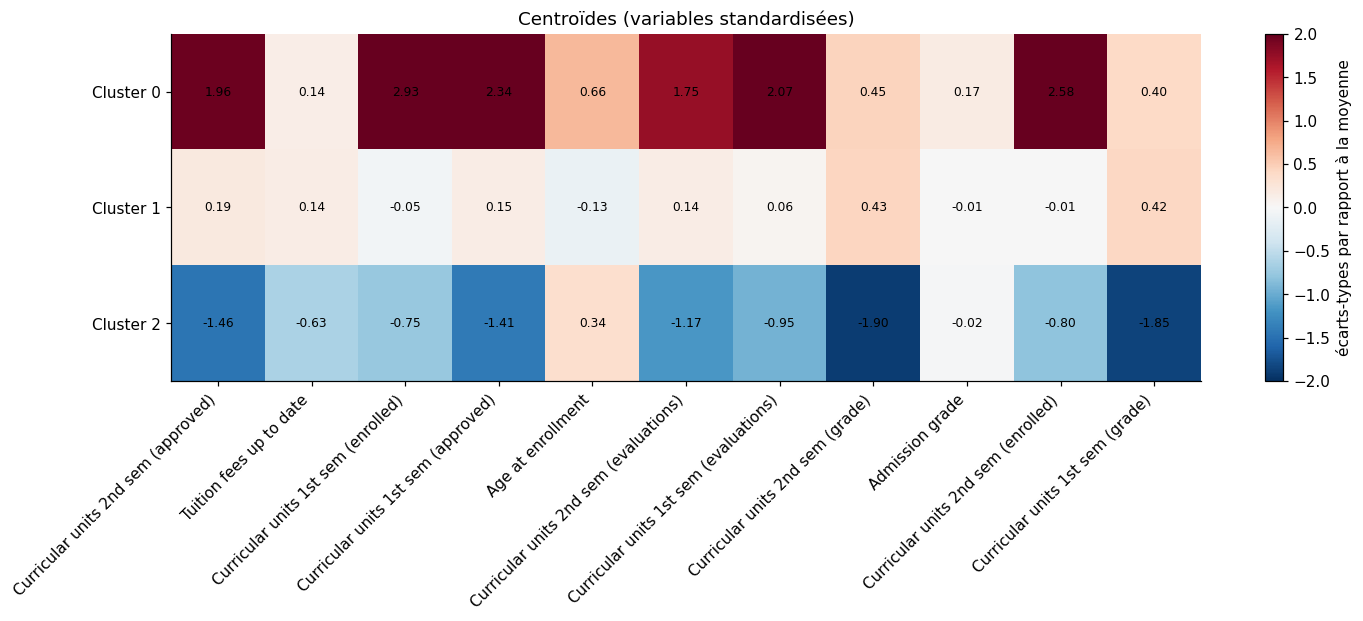

,effectif,Curricular units 2nd sem (approved),Tuition fees up to date,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Age at enrollment,Curricular units 2nd sem (evaluations),Curricular units 1st sem (evaluations),Curricular units 2nd sem (grade),Admission grade,Curricular units 2nd sem (enrolled),Curricular units 1st sem (grade)
Cluster 0,162,10.48,0.92,13.85,12.13,28.36,15.11,17.12,12.63,129.63,12.08,12.64
Cluster 1,2004,5.09,0.92,6.20,5.25,22.36,8.70,8.64,12.50,127.04,6.26,12.71
Cluster 2,487,0.06,0.67,4.40,0.34,25.95,3.48,4.39,0.49,126.88,4.48,1.89


In [32]:
centroids = pd.DataFrame(km.cluster_centers_, columns=features,
                         index=[f"Cluster {c}" for c in range(K)])

fig, ax = plt.subplots(figsize=(1.1 * len(features) + 3, 0.7 * K + 2))
im = ax.imshow(centroids.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(features)), features, rotation=45, ha="right")
ax.set_yticks(range(K), centroids.index)
for i in range(K):
    for j in range(len(features)):
        ax.text(j, i, f"{centroids.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="écarts-types par rapport à la moyenne")
ax.set_title("Centroïdes (variables standardisées)")
plt.savefig(FIGURES / "centroides_heatmap.png", bbox_inches="tight")
plt.show()

profil = clean.loc[X_train.index, features].groupby(train_clusters).mean()
profil.insert(0, "effectif", np.bincount(train_clusters))
profil.index = [f"Cluster {c}" for c in profil.index]
display(profil.round(2))

## 7. Répartition des étiquettes réelles dans chaque cluster

Les étiquettes (Dropout / Enrolled / Graduate) n'ont **pas** été utilisées par K-means. Si un cluster contient une proportion de décrocheurs nettement supérieure au taux global, cela signifie qu'un profil à risque se dégage naturellement des données.

Target,Dropout,Enrolled,Graduate
cluster,,,
0,36,22,104
1,413,415,1176
2,403,39,45


Target,Dropout,Enrolled,Graduate
cluster,,,
0,22.2,13.6,64.2
1,20.6,20.7,58.7
2,82.8,8.0,9.2


Répartition globale (%) :


,global
Target,
Graduate,49.9
Dropout,32.1
Enrolled,17.9


Pureté : 0.634 (référence = classe majoritaire seule : 0.499)
ARI vs étiquettes : 0.139
NMI vs étiquettes : 0.153


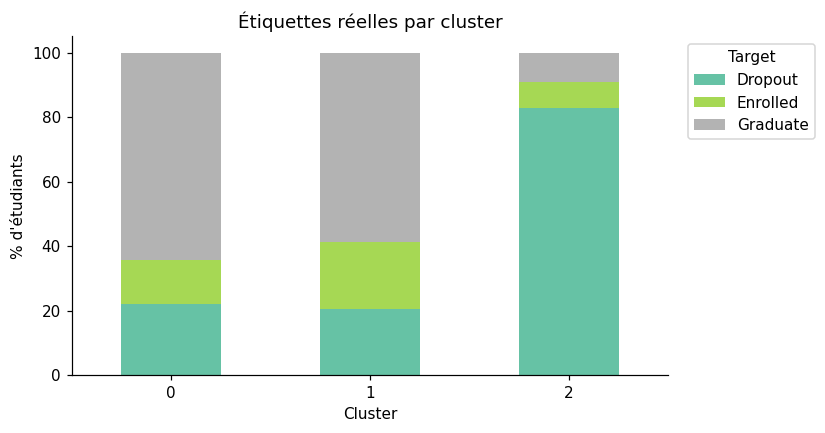

In [33]:
ct = pd.crosstab(pd.Series(train_clusters, name="cluster", index=y.index), y)
pct = ct.div(ct.sum(axis=1), axis=0).mul(100).round(1)
display(ct)
display(pct)

print("Répartition globale (%) :")
display((y.value_counts(normalize=True) * 100).round(1).to_frame("global"))

purete = ct.max(axis=1).sum() / ct.values.sum()
print(f"Pureté : {purete:.3f} (référence = classe majoritaire seule : {y.value_counts(normalize=True).max():.3f})")
print(f"ARI vs étiquettes : {adjusted_rand_score(y, train_clusters):.3f}")
print(f"NMI vs étiquettes : {normalized_mutual_info_score(y, train_clusters):.3f}")

pct.plot(kind="bar", stacked=True, figsize=(7, 4), colormap="Set2")
plt.ylabel("% d'étudiants"); plt.xlabel("Cluster"); plt.xticks(rotation=0)
plt.title("Étiquettes réelles par cluster")
plt.legend(title="Target", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.savefig(FIGURES / "labels_par_cluster.png", bbox_inches="tight")
plt.show()

## 8. Visualisation en 2D (ACP)

L'ACP sert uniquement à la visualisation : K-means a été ajusté dans l'espace complet des caractéristiques retenues.

Variance expliquée : [0.482 0.153]


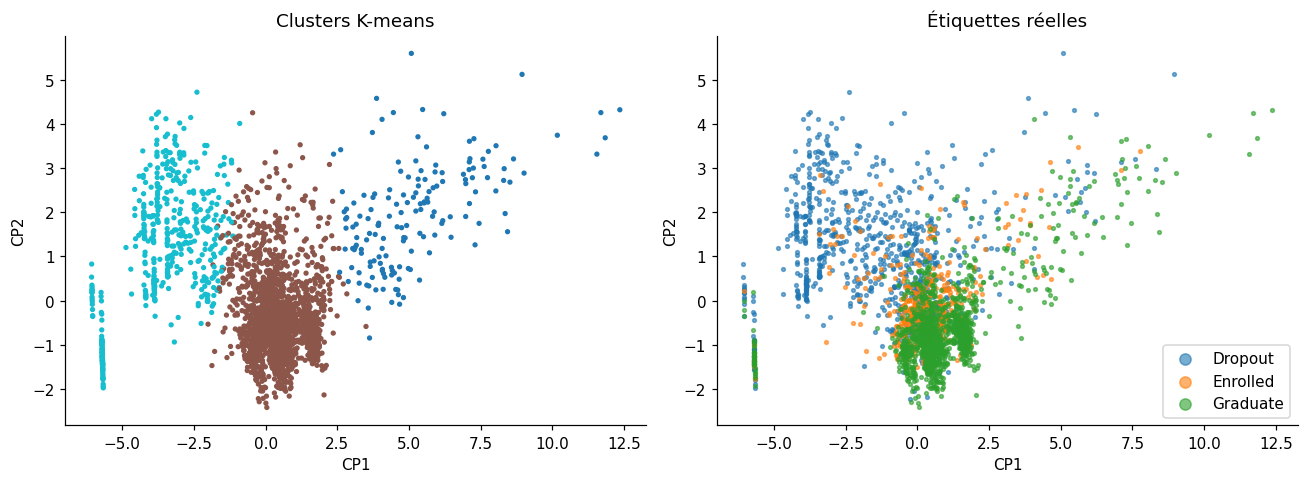

In [34]:
pca = PCA(n_components=2, random_state=SEED).fit(Xtr)
Z = pca.transform(Xtr)
print("Variance expliquée :", pca.explained_variance_ratio_.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sc = axes[0].scatter(Z[:, 0], Z[:, 1], c=train_clusters, s=6, cmap="tab10")
axes[0].set_title("Clusters K-means")
for name, grp in pd.Series(range(len(y)), index=y.index).groupby(y.values):
    axes[1].scatter(Z[grp.values, 0], Z[grp.values, 1], s=6, label=name, alpha=0.6)
axes[1].set_title("Étiquettes réelles"); axes[1].legend(markerscale=3)
for ax in axes:
    ax.set(xlabel="CP1", ylabel="CP2")
plt.tight_layout()
plt.savefig(FIGURES / "pca_clusters.png", bbox_inches="tight")
plt.show()

## 9. Sauvegarde des résultats

In [35]:
pd.DataFrame({"cluster": train_clusters}, index=X_train.index).to_csv(SHARED / "kmeans_clusters_train.csv")
pd.DataFrame({"cluster": val_clusters}, index=X_val.index).to_csv(SHARED / "kmeans_clusters_val.csv")
profil.to_csv(RESULTS / "profils_clusters.csv")
pct.to_csv(RESULTS / "labels_par_cluster_pct.csv")
scores.to_csv(RESULTS / "scores_choix_k.csv")
with open(RESULTS / "kmeans_summary.json", "w", encoding="utf-8") as f:
    json.dump({"k": K, "features": features,
               "silhouette_train": float(silhouette_score(Xtr, train_clusters)),
               "silhouette_val": float(silhouette_score(Xva, val_clusters)),
               "purete": float(purete)}, f, indent=2, ensure_ascii=False)
print("Résultats enregistrés.")

Résultats enregistrés.
